In [1]:
import alpaca
print(alpaca.__version__)
import numpy as np
import matplotlib.pyplot as plt


plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': 'Computer Modern Roman',
    'text.usetex': True,
    'font.size': 9,
    'figure.figsize': (3.375, 2.8),
    'axes.labelsize': 9,
    'axes.titlesize': 10,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'lines.linewidth': 1.2,
    'text.latex.preamble': r'\usepackage{physics}'
})

1.2.0


## EFT analysis

In [17]:
cdsA = np.logspace(-13, -6, 100)
cdsV = np.logspace(-13, -6, 100)
couplingsEFT = np.zeros((100, 100), dtype=object)
lfv = np.array([[0,1,0], [1,0,0], [0,0,0]])*2.0 # Different normalization in ALP-aca vs paper
for i in range(100):
    for j in range(100):
        # We add a huge muon coupling to ensure BR(a -> mu mu) = 1, so that we can use the experimental limit on BR(Sigma+ -> p mu mu) to constrain the couplings.
        couplingsEFT[i, j] = alpaca.ALPcouplings({'cdA': cdsA[i]*lfv, 'cdV': cdsV[j]*lfv, 'ceA':np.diag([0, 10.0, 0])}, 0.26, 'VA_below')

In [18]:
experiment = alpaca.experimental_data.get_measurements('Sigma+ -> p mu mu')['LHCb']

In [19]:
ma = np.linspace(0.214, 0.25, 50)
limits_br = np.array([experiment.get_sigma_right(np.array([m]))[0] for m in ma])

In [20]:
ma[np.argmin(limits_br)]

np.float64(0.2463265306122449)

In [21]:
chi2_246 = alpaca.statistics.get_chi2(['Sigma+ -> p mu mu'], 0.246, couplingsEFT, 1.0, integrator='no_rge')
contour_246 = chi2_246[0].contour(cdsA, cdsV)

In [22]:
ma[np.argmax(limits_br)]

np.float64(0.2286938775510204)

In [23]:
chi2_229 = alpaca.statistics.get_chi2(['Sigma+ -> p mu mu'], 0.229, couplingsEFT, 1.0, integrator='no_rge')
contour_229 = chi2_229[0].contour(cdsA, cdsV)

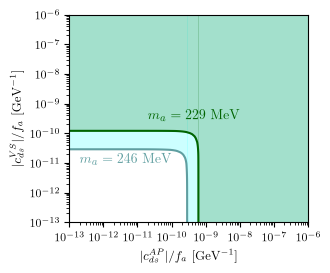

In [25]:
plt.loglog(contour_246[1], contour_246[0], color='cadetblue', linewidth=1.5)
plt.fill_between(contour_246[1], contour_246[0], y2=1e-6, color='aqua', alpha=0.2, lw=0)
plt.fill_between([np.max(contour_246[1]), 1e-6], 1e-13, 1e-6, color='aqua', alpha=0.2, lw=0)

plt.loglog(contour_229[1], contour_229[0], color='darkgreen', linewidth=1.5)
plt.fill_between(contour_229[1], contour_229[0], y2=1e-6, color='darkgreen', alpha=0.2, lw=0)
plt.fill_between([np.max(contour_229[1]), 1e-6], 1e-13, 1e-6, color='darkgreen', alpha=0.2, lw=0)

plt.xlim(1e-13, 1e-6)
plt.ylim(1e-13, 1e-6)
plt.xticks([1e-13, 1e-12, 1e-11, 1e-10, 1e-9, 1e-8, 1e-7, 1e-6])
ax = plt.gca()
from matplotlib.ticker import LogLocator
ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(1.0, 10.0)*0.1, numticks=10))

plt.xlabel(r'$|c_{ds}^{AP}|/f_a$ [GeV$^{-1}$]')
plt.ylabel(r'$|c_{ds}^{VS}|/f_a$ [GeV$^{-1}$]')

plt.text(2e-13, 1e-11, r'$m_a = 246$ MeV', color='cadetblue', fontsize=10)
plt.text(2e-11, 3e-10, r'$m_a = 229$ MeV', color='darkgreen', fontsize=10)

plt.tight_layout()
plt.savefig('sigmapmumu_eft.pdf', dpi=300, bbox_inches='tight')

## QED-DFSZ analysis

In [10]:
ma = np.linspace(0.21, 0.26, 100)
fa = np.logspace(2, 8, 400)

In [11]:
couplings = [alpaca.uvmodels.QED_DFSZ.get_couplings({alpaca.uvmodels.beta: np.pi/4}, 4*np.pi*f).match_run(0.3, 'VA_below') for f in fa]

In [12]:
x_ma, y_fa = np.meshgrid(ma, fa)
x_ma, y_couplings = np.meshgrid(ma, couplings)

chi2 = alpaca.statistics.get_chi2(['Sigma+ -> p mu mu', 'K+ -> pi+ mu mu', 'K+ -> pi+ a'], x_ma, y_couplings, y_fa, integrator='no_rge')

In [13]:
chi2

|Index|Sector|
| :-: | :- |
|0|$$\Sigma^+ \to \mu \mu p$$|
|1|$$K^+ \to \mu \mu \pi^+$$|
|2|$$K^+ \to a \pi^+$$|

In [14]:
contours_sigma = chi2[0].contour(x_ma, y_fa)
contours_kpimimi = chi2[1].contour(x_ma, y_fa)
contours_kpinv = chi2[2].contour(x_ma, y_fa)

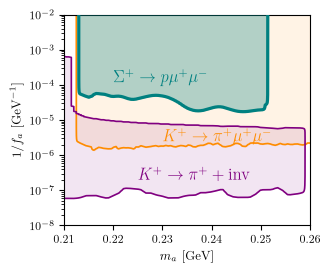

In [15]:
plt.semilogy(contours_sigma[0], 1/contours_sigma[1], c='teal', label=r'$\Sigma^+ \to p \mu^+ \mu^-$', zorder=10, lw=2.3)
plt.fill_between(contours_sigma[0], 1/contours_sigma[1], 1e-2, color='teal', alpha=0.3, zorder=10)

plt.semilogy(contours_kpimimi[0], 1/contours_kpimimi[1], c='darkorange', label=r'$K^+ \to \pi^+ \mu^+ \mu^-$')
plt.fill_between(contours_kpimimi[0], 1/contours_kpimimi[1], 1e-2, color='darkorange', alpha=0.1)

plt.semilogy(contours_kpinv[0], 1/contours_kpinv[1], c='purple', label=r'$K^+ \to \pi^+ a$')
plt.fill_between(contours_kpinv[0], 1/contours_kpinv[1], 1e-2, color='purple', alpha=0.1, linewidth=0)

plt.xlim(0.21, 0.26)
plt.ylim(1e-8, 1e-2)

plt.text(0.22, 1.2e-4, r'$\Sigma^+ \to p \mu^+ \mu^-$', color='teal', fontsize=12)
plt.text(0.23, 2.5e-6, r'$K^+ \to \pi^+ \mu^+ \mu^-$', color='darkorange', fontsize=12)
plt.text(0.225, 2e-7, r'$K^+ \to \pi^+ + \mathrm{inv}$', color='purple', fontsize=12)

plt.xlabel(r'$m_a$ [GeV]')
plt.ylabel(r'$1/f_a$ [GeV$^{-1}$]')

plt.tight_layout()
plt.savefig('bounds_sda.pdf', dpi=300, bbox_inches='tight')

In [16]:
chi2.citation_report('measurements_sigmapmumu')